# Quinta lista de ejercicios

**Introducción al Machine Learning — Quinta lista de ejercicios: selección de variables y generalización**
Universidad El Bosque · Programa de Matemáticas y Estadística · Semestre 2026–2
**Autor:** Daniel Vargas

Se trabaja con `hitters.csv` (263 jugadores de béisbol; objetivo `Salary`, en miles de dólares; 19 predictoras).
Todos los modelos son regresiones lineales con intercepto y el riesgo es el cuadrático
$\hat R_S(h)=\frac1{|S|}\sum_{i\in S}(y_i-h(x_i))^2$, calculado con una función propia (`lista5.riesgo_cuadratico`).

**Reglas de la lista.** Los modelos se ajustan **solo con entrenamiento**; la validación se usa para comparar modelos (ejercicios 1–3);
el conjunto de prueba se reserva para el ejercicio 4.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from lista5 import (
    ajustar_y_evaluar,
    cargar_hitters,
    correlaciones_con_objetivo,
    particionar,
    pvalores_t,
    seleccion_hacia_adelante,
)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

OBJETIVO = "Salary"
df = cargar_hitters()
predictoras = [c for c in df.columns if c != OBJETIVO]
print("Datos:", df.shape, "| n.º de predictoras:", len(predictoras))
df.head()

Datos: (263, 20) | n.º de predictoras: 19


,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,League,Division,PutOuts,Assists,Errors,NewLeague,Salary
0,315,81,7,24,38,39,14,3449,835,69,321,414,375,1,1,632,43,10,1,475.0000
1,479,130,18,66,72,76,3,1624,457,63,224,266,263,0,1,880,82,14,0,480.0000
2,496,141,20,65,78,37,11,5628,1575,225,828,838,354,1,0,200,11,3,1,500.0000
3,321,87,10,39,42,30,2,396,101,12,48,46,33,1,0,805,40,4,1,91.5000
4,594,169,4,74,51,35,11,4408,1133,19,501,336,194,0,1,282,421,25,0,750.0000


## Partición de los datos

`train_test_split` con `random_state=31`, en dos etapas: 120 de desarrollo / 143 de prueba y, luego, 50 de entrenamiento / 70 de validación.

In [2]:
entrenamiento, validacion, prueba = particionar(df, n_desarrollo=120, n_entrenamiento=50, random_state=31)

print("entrenamiento:", len(entrenamiento), "| validación:", len(validacion), "| prueba:", len(prueba))
# Los tres conjuntos deben ser disjuntos
assert not (set(entrenamiento.index) & set(validacion.index))
assert not (set(entrenamiento.index) & set(prueba.index))
assert not (set(validacion.index) & set(prueba.index))

entrenamiento: 50 | validación: 70 | prueba: 143


# Ejercicio 1. Modelo completo

(a) y (b): regresión lineal con las 19 variables, riesgos de entrenamiento y validación.

In [3]:
modelo_completo = ajustar_y_evaluar(entrenamiento, validacion, predictoras, OBJETIVO)

pd.DataFrame(
    {"riesgo": [modelo_completo["riesgo_train"], modelo_completo["riesgo_val"]]},
    index=["entrenamiento", "validación"],
)

,riesgo
entrenamiento,"68,584.8164"
validación,"320,423.1919"


El modelo completo tiene un riesgo de entrenamiento de ≈ 68 585 y de validación de ≈ 320 423, casi cinco veces mayor.
Con solo 50 observaciones de entrenamiento y 20 parámetros (19 coeficientes + intercepto), el modelo se ajusta muy bien a los datos con que se entrenó pero generaliza mal: **sobreajuste**.

# Ejercicio 2. Selección estadística de variables

## (a) Correlación de Pearson con `Salary` (solo entrenamiento)

In [4]:
tabla_corr = correlaciones_con_objetivo(entrenamiento, OBJETIVO)
tabla_corr

,correlacion,abs_correlacion
CRBI,0.4333,0.4333
CRuns,0.4252,0.4252
CHmRun,0.4181,0.4181
CHits,0.4165,0.4165
CAtBat,0.3835,0.3835
CWalks,0.2915,0.2915
Years,0.2414,0.2414
PutOuts,0.1926,0.1926
HmRun,0.1833,0.1833
RBI,0.1813,0.1813


## (b) Regresión con las siete variables de mayor correlación

In [5]:
top7 = list(tabla_corr.index[:7])
modelo_top7 = ajustar_y_evaluar(entrenamiento, validacion, top7, OBJETIVO)

print("Variables (mayor |correlación|):", top7)
pd.DataFrame(
    {"riesgo": [modelo_top7["riesgo_train"], modelo_top7["riesgo_val"]]},
    index=["entrenamiento", "validación"],
)

Variables (mayor |correlación|): ['CRBI', 'CRuns', 'CHmRun', 'CHits', 'CAtBat', 'CWalks', 'Years']


,riesgo
entrenamiento,"115,487.2485"
validación,"133,035.6122"


## (c) Valores p de la prueba t en la regresión completa y selección con $p<0{,}05$

Los valores p se calculan con `lista5.pvalores_t` (MCO con $\hat\sigma^2=RSS/(n-p-1)$, 30 grados de libertad).

In [6]:
tabla_p = pvalores_t(entrenamiento, predictoras, OBJETIVO)
tabla_p.sort_values("valor_p")

,coeficiente,error_est,t,valor_p
intercepto,856.7220,260.0849,3.2940,0.0025
AtBat,-6.4584,2.1123,-3.0575,0.0047
Assists,2.2501,0.8671,2.5950,0.0145
CWalks,-2.5182,1.1633,-2.1648,0.0385
Runs,17.4928,9.4958,1.8422,0.0754
Errors,-28.1610,15.6520,-1.7992,0.0821
RBI,16.9727,10.0343,1.6915,0.1011
Years,-47.8583,36.5674,-1.3088,0.2005
CRuns,2.2719,2.4780,0.9168,0.3665
NewLeague,151.0570,191.9665,0.7869,0.4375


In [7]:
seleccion_t = [v for v in predictoras if tabla_p.loc[v, "valor_p"] < 0.05]
modelo_t = ajustar_y_evaluar(entrenamiento, validacion, seleccion_t, OBJETIVO)

print("Variables con p < 0,05:", seleccion_t)
pd.DataFrame(
    {"riesgo": [modelo_t["riesgo_train"], modelo_t["riesgo_val"]]},
    index=["entrenamiento", "validación"],
)

Variables con p < 0,05: ['AtBat', 'CWalks', 'Assists']


,riesgo
entrenamiento,"161,221.3618"
validación,"140,085.1870"


## (d) Variables seleccionadas y comparación

In [8]:
comparacion_2 = pd.DataFrame(
    {
        "variables": [", ".join(predictoras), ", ".join(top7), ", ".join(seleccion_t)],
        "n_variables": [19, len(top7), len(seleccion_t)],
        "riesgo_train": [modelo_completo["riesgo_train"], modelo_top7["riesgo_train"], modelo_t["riesgo_train"]],
        "riesgo_val": [modelo_completo["riesgo_val"], modelo_top7["riesgo_val"], modelo_t["riesgo_val"]],
    },
    index=["Todas las variables", "Mayor correlación", "Pruebas t"],
)
print("Variables en común entre correlación y pruebas t:", sorted(set(top7) & set(seleccion_t)))
comparacion_2

Variables en común entre correlación y pruebas t: ['CWalks']


,variables,n_variables,riesgo_train,riesgo_val
Todas las variables,"AtBat, Hits, HmRun, Runs, RBI, Walks, Years, C...",19,"68,584.8164","320,423.1919"
Mayor correlación,"CRBI, CRuns, CHmRun, CHits, CAtBat, CWalks, Years",7,"115,487.2485","133,035.6122"
Pruebas t,"AtBat, CWalks, Assists",3,"161,221.3618","140,085.1870"


**Respuesta.**

* **Mayor correlación** selecciona `CRBI, CRuns, CHmRun, CHits, CAtBat, CWalks, Years`: casi todas son estadísticas acumuladas de carrera. **Pruebas t** selecciona `AtBat, CWalks, Assists`. La única variable común es `CWalks`.
* Frente al modelo completo, ambos criterios **aumentan** el riesgo de entrenamiento (68 585 → 115 487 con correlación y 161 221 con pruebas t), como era de esperar al quitar variables, pero **reducen mucho** el riesgo de validación (320 423 → 133 036 y 140 085). Es decir, generalizan mejor.
* El criterio de correlación es mejor que el de pruebas t en ambos riesgos (115 487 / 133 036 frente a 161 221 / 140 085).
* Las pruebas t del modelo completo se calculan con solo 30 grados de libertad y con predictoras muy correlacionadas entre sí (`CAtBat`, `CHits`, `CRuns`, `CRBI`…). Esa multicolinealidad infla los errores estándar y hace que ninguna de ellas parezca significativa individualmente, aunque en conjunto sí son informativas. Por eso este criterio descarta justo las variables que más correlación tienen con el salario.

# Ejercicio 3. Selección hacia adelante

Se empieza con la variable de menor riesgo de entrenamiento y en cada paso se agrega la que más lo disminuya, sin retirar las anteriores, hasta usar las 19 (`lista5.seleccion_hacia_adelante`). La validación solo se registra; **no** interviene en la elección de cada variable.

## (a) Tabla de pasos

In [9]:
pasos = seleccion_hacia_adelante(entrenamiento, validacion, predictoras, OBJETIVO)
tabla_pasos = pasos[["n_variables", "variable_agregada", "riesgo_train", "riesgo_val"]].set_index("n_variables")
tabla_pasos

,variable_agregada,riesgo_train,riesgo_val
n_variables,,,
1,CRBI,"144,809.3173","146,285.3948"
2,Years,"131,715.6911","142,801.7070"
3,CRuns,"126,982.3235","130,618.1981"
4,AtBat,"123,026.4367","148,610.2362"
5,Hits,"113,273.7562","134,668.7540"
6,CWalks,"104,271.8696","162,725.8921"
7,RBI,"97,143.2416","196,523.6458"
8,Assists,"92,928.7447","188,600.4397"
9,Errors,"87,364.0158","211,733.4913"


## (b) Riesgos según el número de variables

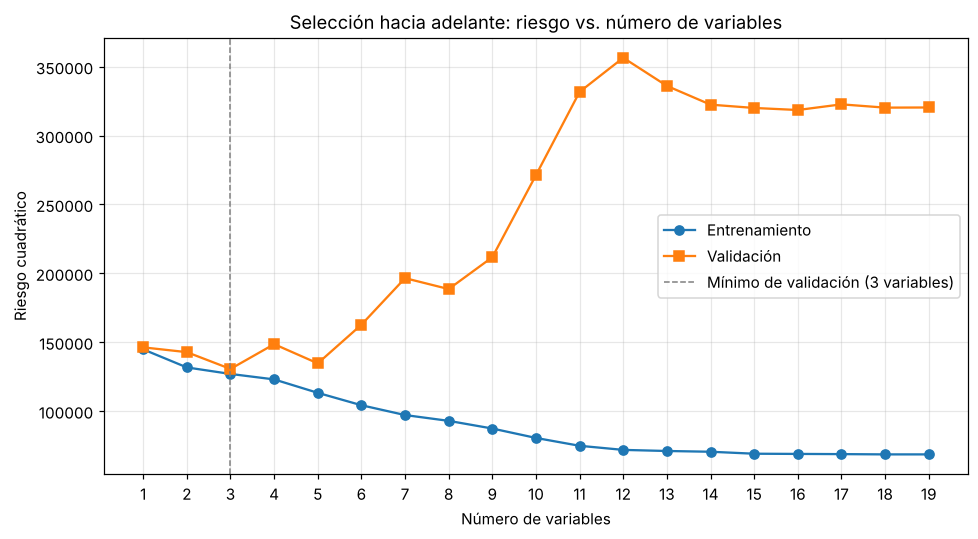

In [10]:
mejor = pasos.loc[pasos["riesgo_val"].idxmin()]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(pasos["n_variables"], pasos["riesgo_train"], marker="o", label="Entrenamiento")
ax.plot(pasos["n_variables"], pasos["riesgo_val"], marker="s", label="Validación")
ax.axvline(mejor["n_variables"], color="gray", ls="--", lw=1,
           label=f"Mínimo de validación ({int(mejor['n_variables'])} variables)")
ax.set_xticks(range(1, 20))
ax.set_xlabel("Número de variables")
ax.set_ylabel("Riesgo cuadrático")
ax.set_title("Selección hacia adelante: riesgo vs. número de variables")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()

## (c) Modelo con menor riesgo de validación

In [11]:
variables_adelante = list(mejor["variables"])
print(f"Menor riesgo de validación: {mejor['riesgo_val']:,.4f} con {int(mejor['n_variables'])} variables")
print("Variables:", variables_adelante)

Menor riesgo de validación: 130,618.1981 con 3 variables
Variables: ['CRBI', 'Years', 'CRuns']


**Respuesta.** El menor riesgo de validación (≈ 130 618) se alcanza con **3 variables: `CRBI`, `Years` y `CRuns`**.
El riesgo de entrenamiento baja siempre al agregar variables (el modelo es anidado), pero el de validación sube después de 3 variables y llega a ≈ 320 000 con las 19: a partir de ahí, las variables adicionales solo ajustan ruido del conjunto de entrenamiento.

# Ejercicio 4. Comparación final

Se elige un modelo **solo con los riesgos de validación** y luego se evalúan los cuatro en el conjunto de prueba.

In [12]:
modelos = {
    "Todas las variables": predictoras,
    "Mayor correlación": top7,
    "Pruebas t": seleccion_t,
    "Selección hacia adelante": variables_adelante,
}

evaluaciones = {
    nombre: ajustar_y_evaluar(entrenamiento, validacion, vars_, OBJETIVO, prueba=prueba)
    for nombre, vars_ in modelos.items()
}

tabla_final = pd.DataFrame(
    {
        "Variables": [", ".join(v) for v in modelos.values()],
        "Riesgo train": [e["riesgo_train"] for e in evaluaciones.values()],
        "Riesgo validación": [e["riesgo_val"] for e in evaluaciones.values()],
        "Riesgo prueba": [e["riesgo_prueba"] for e in evaluaciones.values()],
    },
    index=pd.Index(modelos.keys(), name="Modelo"),
)
tabla_final

,Variables,Riesgo train,Riesgo validación,Riesgo prueba
Modelo,,,,
Todas las variables,"AtBat, Hits, HmRun, Runs, RBI, Walks, Years, C...","68,584.8164","320,423.1919","394,308.6934"
Mayor correlación,"CRBI, CRuns, CHmRun, CHits, CAtBat, CWalks, Years","115,487.2485","133,035.6122","145,923.2919"
Pruebas t,"AtBat, CWalks, Assists","161,221.3618","140,085.1870","158,772.4728"
Selección hacia adelante,"CRBI, Years, CRuns","126,982.3235","130,618.1981","126,939.5956"


## (a) Modelo elegido con validación

In [13]:
elegido = tabla_final["Riesgo validación"].idxmin()
print(f"Modelo elegido: {elegido}")
print(f"Riesgo de validación: {tabla_final.loc[elegido, 'Riesgo validación']:,.4f}")

Modelo elegido: Selección hacia adelante
Riesgo de validación: 130,618.1981


## (c), (d) Menor riesgo de entrenamiento y de prueba

In [14]:
menor_train = tabla_final["Riesgo train"].idxmin()
menor_prueba = tabla_final["Riesgo prueba"].idxmin()
print(f"Menor riesgo de entrenamiento: {menor_train} ({tabla_final.loc[menor_train, 'Riesgo train']:,.4f})")
print(f"Menor riesgo de prueba:        {menor_prueba} ({tabla_final.loc[menor_prueba, 'Riesgo prueba']:,.4f})")
print("¿Coinciden?", menor_train == menor_prueba)
print("¿El elegido con validación tuvo el menor riesgo de prueba?", elegido == menor_prueba)

Menor riesgo de entrenamiento: Todas las variables (68,584.8164)
Menor riesgo de prueba:        Selección hacia adelante (126,939.5956)
¿Coinciden? False
¿El elegido con validación tuvo el menor riesgo de prueba? True


**Respuestas.**

**(a)** Se eligió **Selección hacia adelante** (`CRBI`, `Years`, `CRuns`), el modelo con menor riesgo de validación entre los cuatro: ≈ 130 618 (frente a 133 036 de Mayor correlación, 140 085 de Pruebas t y 320 423 del modelo completo).

**(b)** Ver la tabla anterior.

**(c)** El menor riesgo de **entrenamiento** lo tiene **Todas las variables** (≈ 68 585) y el menor riesgo de **prueba** lo tiene **Selección hacia adelante** (≈ 126 940). **No coinciden**: el modelo que mejor se ajusta a los datos de entrenamiento es el peor en prueba (≈ 394 309). Tener el menor riesgo de entrenamiento no garantiza buena generalización; es el sobreajuste de un modelo de 20 parámetros con 50 observaciones.

**(d)** **Sí.** El modelo escogido con validación (Selección hacia adelante) fue el de menor riesgo de prueba: 126 940, frente a 145 923 (Mayor correlación), 158 772 (Pruebas t) y 394 309 (Todas las variables). El orden de los modelos por riesgo de validación coincide con el orden por riesgo de prueba.

*Observación.* La selección hacia adelante usó el riesgo de entrenamiento para decidir qué variable agregar, pero la validación para decidir *cuántas* variables conservar; por eso el riesgo de validación de ese modelo es algo optimista, y es el conjunto de prueba el que da la medida honesta de generalización. Además, con 50 observaciones de entrenamiento y 70 de validación, estas diferencias entre modelos pueden variar con otra partición.